# 03. Нейросетевой Baseline на PyTorch (`nn.Module`) поверх char TF-IDF

* Признаки — сохранённый `models/tfidf_vectorizer.pkl` (char n-граммы, без лемматизации).
* Архитектура строго по ТЗ: `Linear(in, 128) → ReLU → Linear(128, num_classes)`, на выходе **сырые логиты**.
* Разбиение: 80 % train / 20 % test (`random_state=42`). Разбиение делается **по документам**
  (`GroupShuffleSplit`), чтобы фрагменты одного документа не попали одновременно в обе части.
* Дополнительно модель оценивается на официальной **test**-выборке датасета — на ней же
  оценивается ruBERT + LoRA, что делает сравнение честным.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import torch
import torch.nn as nn
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED, MODELS, FIG, REPORTS = ROOT / "data/processed", ROOT / "models", ROOT / "reports/figures", ROOT / "reports"
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
sns.set_theme(style="whitegrid")

device: cuda NVIDIA GeForce RTX 5070


In [2]:
vectorizer = joblib.load(MODELS / "tfidf_vectorizer.pkl")
label_encoder = joblib.load(MODELS / "label_encoder.pkl")
print(vectorizer)
print("classes:", len(label_encoder.classes_))

train_df = pd.read_parquet(PROCESSED / "chunks_train.parquet")
test_df = pd.read_parquet(PROCESSED / "chunks_test.parquet")

TfidfVectorizer(analyzer='char', dtype=<class 'numpy.float32'>,
                max_features=50000, ngram_range=(2, 4), sublinear_tf=True)
classes: 64


### Векторизация (параллельно по 8 процессам)

In [3]:
def vectorize(texts: list[str], n_jobs: int = 8) -> sp.csr_matrix:
    parts = np.array_split(np.arange(len(texts)), n_jobs * 4)
    mats = Parallel(n_jobs=n_jobs)(delayed(vectorizer.transform)([texts[i] for i in p]) for p in parts)
    return sp.vstack(mats).tocsr().astype(np.float32)


t0 = time.perf_counter()
X = vectorize(train_df["text"].tolist())
X_official_test = vectorize(test_df["text"].tolist())
y = label_encoder.transform(train_df["author"])
y_official_test = label_encoder.transform(test_df["author"])
print(f"X: {X.shape}, nnz/row={X.nnz / X.shape[0]:.0f}, {time.perf_counter() - t0:.0f} c")

X: (110285, 50000), nnz/row=1724, 21 c


### Разбиение 80 / 20 (`random_state=42`, группировка по документу)

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups=train_df["doc_id"]))
X_tr, X_te, y_tr, y_te = X[tr_idx], X[te_idx], y[tr_idx], y[te_idx]
print("train:", X_tr.shape, "| test:", X_te.shape)
print("Пересечение документов:", len(set(train_df.doc_id.iloc[tr_idx]) & set(train_df.doc_id.iloc[te_idx])))

train: (88202, 50000) | test: (22083, 50000)
Пересечение документов: 0


### Архитектура (строго по ТЗ)

In [5]:
class TextClassifier(nn.Module):
    def __init__(self, in_features: int, num_classes: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),  # На выходе СЫРЫЕ ЛОГИТЫ! Без Softmax!
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


num_classes = len(label_encoder.classes_)
model = TextClassifier(X.shape[1], num_classes).to(device)
optim = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()  # внутри log_softmax + nll_loss
print(model)
print("Параметров:", sum(p.numel() for p in model.parameters()))

TextClassifier(
  (net): Sequential(
    (0): Linear(in_features=50000, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
  )
)
Параметров: 6408384


### DataLoader и плотные мини-батчи «на лету»
`TensorDataset` хранит индексы строк и метки; разреженная CSR-матрица остаётся в RAM, а в
плотный тензор переводится только текущий батч из 32 строк.

In [6]:
train_ds = TensorDataset(torch.arange(X_tr.shape[0]), torch.as_tensor(y_tr, dtype=torch.long))
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)


def to_dense_batch(X_sparse: sp.csr_matrix, idx) -> torch.Tensor:
    return torch.from_numpy(X_sparse[idx].toarray()).to(device, non_blocking=True)


@torch.no_grad()
def predict_logits(X_sparse: sp.csr_matrix, batch_size: int = 256) -> torch.Tensor:
    model.eval()
    out = []
    for start in range(0, X_sparse.shape[0], batch_size):
        out.append(model(to_dense_batch(X_sparse, slice(start, min(start + batch_size, X_sparse.shape[0])))).cpu())
    return torch.cat(out)


def evaluate(X_sparse, y_true):
    logits = predict_logits(X_sparse)
    loss = criterion(logits, torch.as_tensor(y_true, dtype=torch.long)).item()
    preds = logits.argmax(dim=1).numpy()
    return loss, accuracy_score(y_true, preds), f1_score(y_true, preds, average="macro")

### Обучение: 20 эпох, Adam(lr=1e-3), CrossEntropyLoss

In [7]:
EPOCHS = 20
history = []
t_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    total, n = 0.0, 0
    for idx, yb in train_loader:
        xb = to_dense_batch(X_tr, idx.numpy())
        yb = yb.to(device)
        optim.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optim.step()
        total += loss.item() * len(yb)
        n += len(yb)
    train_loss = total / n
    te_loss, te_acc, te_f1 = evaluate(X_te, y_te)
    history.append({"epoch": epoch, "train_loss": train_loss, "test_loss": te_loss, "test_acc": te_acc, "test_f1_macro": te_f1})
    print(f"epoch {epoch:2d} | train loss {train_loss:.4f} | test loss {te_loss:.4f} | acc {te_acc:.4f} | macro-F1 {te_f1:.4f}")
train_time = time.perf_counter() - t_start
print(f"Время обучения: {train_time / 60:.1f} мин")

hist = pd.DataFrame(history)
hist.to_csv(REPORTS / "baseline_history.csv", index=False)

epoch  1 | train loss 1.3386 | test loss 0.4933 | acc 0.8863 | macro-F1 0.7038


epoch  2 | train loss 0.1733 | test loss 0.2882 | acc 0.9305 | macro-F1 0.8381


epoch  3 | train loss 0.0282 | test loss 0.2379 | acc 0.9396 | macro-F1 0.8758


epoch  4 | train loss 0.0056 | test loss 0.2273 | acc 0.9362 | macro-F1 0.8485


epoch  5 | train loss 0.0026 | test loss 0.2130 | acc 0.9424 | macro-F1 0.8743


epoch  6 | train loss 0.0017 | test loss 0.2120 | acc 0.9424 | macro-F1 0.8901


... (10 outputs left out)

epoch 17 | train loss 0.0001 | test loss 0.3037 | acc 0.9423 | macro-F1 0.8849


epoch 18 | train loss 0.0001 | test loss 0.3131 | acc 0.9420 | macro-F1 0.8869


epoch 19 | train loss 0.0000 | test loss 0.3089 | acc 0.9417 | macro-F1 0.8746


epoch 20 | train loss 0.0001 | test loss 0.3153 | acc 0.9418 | macro-F1 0.8726
Время обучения: 2.6 мин


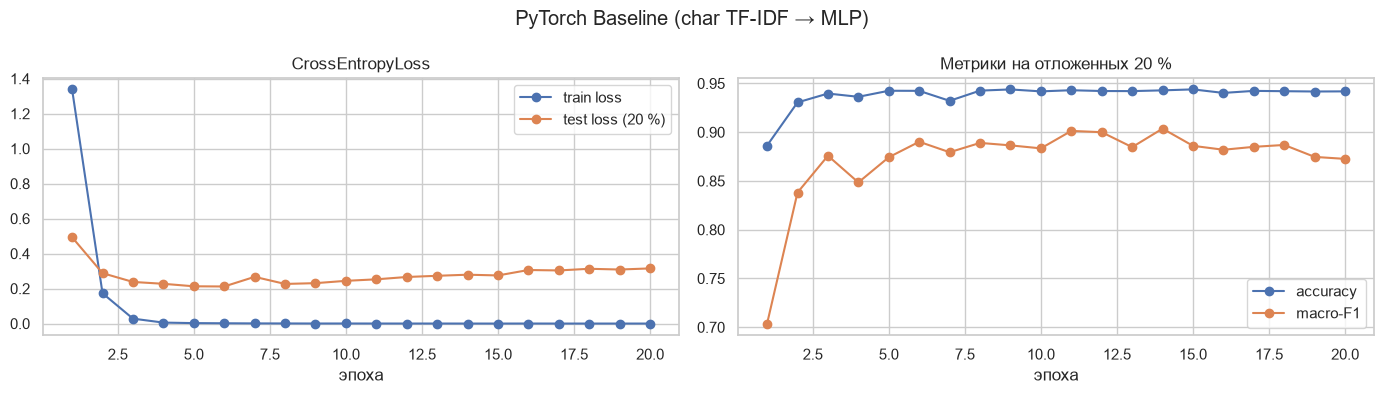

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hist.epoch, hist.train_loss, "o-", label="train loss")
axes[0].plot(hist.epoch, hist.test_loss, "o-", label="test loss (20 %)")
axes[0].set_xlabel("эпоха")
axes[0].set_title("CrossEntropyLoss")
axes[0].legend()
axes[1].plot(hist.epoch, hist.test_acc, "o-", label="accuracy")
axes[1].plot(hist.epoch, hist.test_f1_macro, "o-", label="macro-F1")
axes[1].set_xlabel("эпоха")
axes[1].set_title("Метрики на отложенных 20 %")
axes[1].legend()
plt.suptitle("PyTorch Baseline (char TF-IDF → MLP)")
plt.tight_layout()
plt.savefig(FIG / "baseline_training.png", dpi=120)
plt.show()

### Валидация: `model.eval()` + `torch.no_grad()` + `argmax`

Отложенные 20 % train (фрагменты): {'accuracy': 0.9418104424217724, 'f1_macro': 0.8725954657560154}


Официальный test (фрагменты ~1000 симв.): {'accuracy': 0.9434755847353303, 'f1_macro': 0.8867041328067355}
Официальный test (документы, ~14 000 симв.): {'accuracy': 0.9929378531073446, 'f1_macro': 0.9685278699177139}


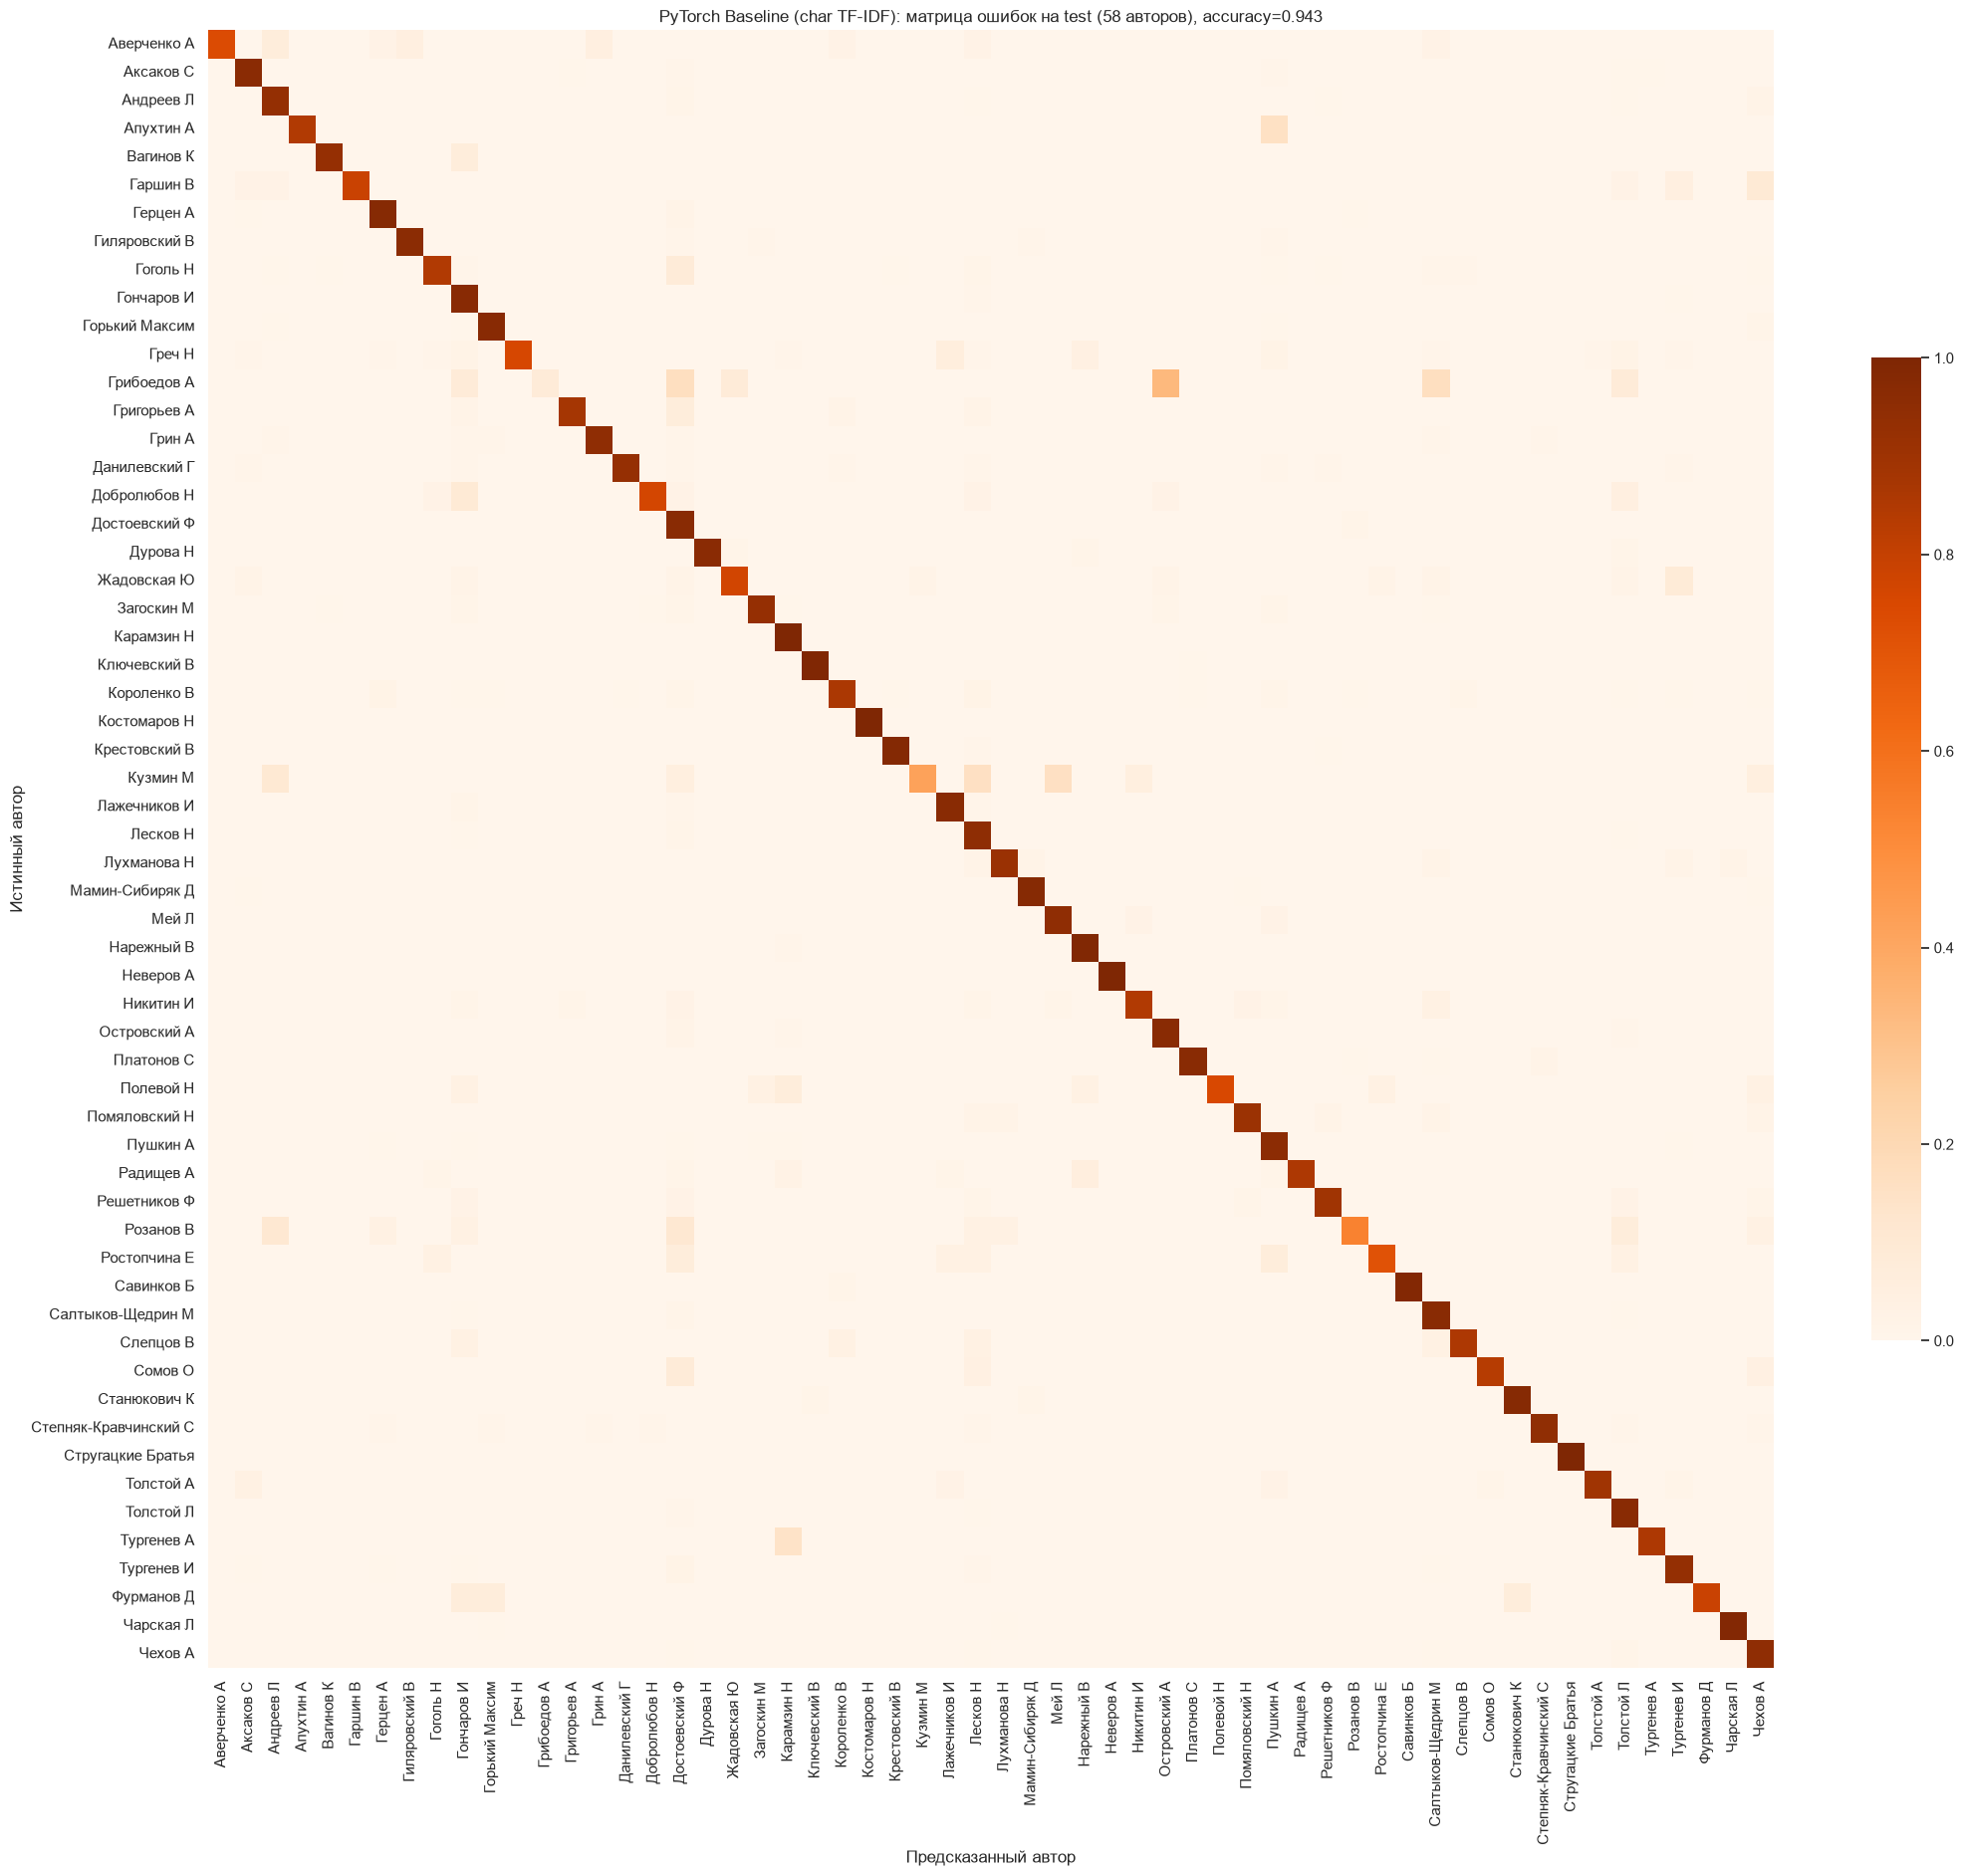

In [9]:
model.eval()
with torch.no_grad():
    logits = predict_logits(X_te)
    preds = logits.argmax(dim=1).numpy()
holdout = {"accuracy": accuracy_score(y_te, preds), "f1_macro": f1_score(y_te, preds, average="macro")}
print("Отложенные 20 % train (фрагменты):", holdout)

with torch.no_grad():
    logits_off = predict_logits(X_official_test)
probs_off = torch.softmax(logits_off, dim=1).numpy()
preds_off = probs_off.argmax(1)
chunk_metrics = {"accuracy": accuracy_score(y_official_test, preds_off), "f1_macro": f1_score(y_official_test, preds_off, average="macro")}
print("Официальный test (фрагменты ~1000 симв.):", chunk_metrics)

# Документ-уровень: усреднение вероятностей по фрагментам документа
doc_probs = pd.DataFrame(probs_off).groupby(test_df["doc_id"].values).mean()
doc_true = test_df.groupby("doc_id")["author"].first().loc[doc_probs.index]
doc_pred = label_encoder.classes_[doc_probs.values.argmax(1)]
doc_metrics = {"accuracy": accuracy_score(doc_true, doc_pred), "f1_macro": f1_score(doc_true, doc_pred, average="macro")}
print("Официальный test (документы, ~14 000 симв.):", doc_metrics)

# Матрица ошибок Baseline на официальном test
test_labels = np.unique(y_official_test)
cm_base = confusion_matrix(y_official_test, preds_off, labels=test_labels, normalize="true")
fig, ax = plt.subplots(figsize=(22, 19))
sns.heatmap(
    cm_base,
    cmap="Oranges",
    ax=ax,
    xticklabels=[label_encoder.classes_[i] for i in test_labels],
    yticklabels=[label_encoder.classes_[i] for i in test_labels],
    vmin=0,
    vmax=1,
    cbar_kws={"shrink": 0.6},
)
ax.set_xlabel("Предсказанный автор")
ax.set_ylabel("Истинный автор")
ax.set_title(f"PyTorch Baseline (char TF-IDF): матрица ошибок на test ({len(test_labels)} авторов), accuracy={chunk_metrics['accuracy']:.3f}")
plt.tight_layout()
plt.savefig(FIG / "baseline_confusion_matrix.png", dpi=110)
plt.show()

### Сохранение чекпоинта (`state_dict`) и проверка восстановления

In [10]:
ckpt_path = MODELS / "baseline_pytorch.pt"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optim_state_dict": optim.state_dict(),
        "epoch": EPOCHS,
        "in_features": X.shape[1],
        "num_classes": len(label_encoder.classes_),
        "classes": label_encoder.classes_.tolist(),
    },
    ckpt_path,
)
print(f"{ckpt_path.name}: {ckpt_path.stat().st_size / 2**20:.1f} MB")

ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)
restored = TextClassifier(ckpt["in_features"], ckpt["num_classes"])
restored.load_state_dict(ckpt["model_state_dict"])
restored.eval()
with torch.no_grad():
    sample = torch.from_numpy(X_te[:256].toarray())
    same = (restored(sample).argmax(1).numpy() == preds[:256]).all()
print("Восстановленная модель даёт те же предсказания:", bool(same))

baseline_pytorch.pt: 73.3 MB
Восстановленная модель даёт те же предсказания: True


### Латентность инференса (векторизация + MLP + softmax, CPU, один запрос)

In [11]:
restored_cpu = restored.cpu()
texts = test_df["text"].sample(100, random_state=SEED).tolist()
t0 = time.perf_counter()
with torch.no_grad():
    for t in texts:
        x = torch.from_numpy(vectorizer.transform([t]).toarray())
        torch.softmax(restored_cpu(x), dim=1)
latency_ms = (time.perf_counter() - t0) / len(texts) * 1000

latency_gpu_ms = None
if device.type == "cuda":
    restored_gpu = restored.to(device).eval()
    with torch.no_grad():
        for t in texts[:5]:
            restored_gpu(torch.from_numpy(vectorizer.transform([t]).toarray()).to(device))
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        for t in texts:
            xg = torch.from_numpy(vectorizer.transform([t]).toarray()).to(device)
            torch.softmax(restored_gpu(xg), dim=1).cpu()
        torch.cuda.synchronize()
    latency_gpu_ms = (time.perf_counter() - t0) / len(texts) * 1000
gpu_str = f"{latency_gpu_ms:.2f}" if latency_gpu_ms is not None else "N/A"
print(f"CPU latency: {latency_ms:.2f} мс / запрос | GPU latency: {gpu_str} мс / запрос")

CPU latency: 1.99 мс / запрос | GPU latency: 1.34 мс / запрос


In [12]:
metrics = {
    "model": "PyTorch MLP (char TF-IDF)",
    "holdout_20pct": holdout,
    "best_holdout_f1_macro": float(hist["test_f1_macro"].max()),
    "best_holdout_epoch": int(hist.loc[hist["test_f1_macro"].idxmax(), "epoch"]),
    "official_test_chunks": chunk_metrics,
    "official_test_docs": doc_metrics,
    "train_time_min": train_time / 60,
    "latency_cpu_ms": latency_ms,
    "latency_gpu_ms": latency_gpu_ms,
    "weights_mb": ckpt_path.stat().st_size / 2**20,
    "weights_model_only_mb": sum(p.numel() for p in model.parameters()) * 4 / 2**20,
    "vectorizer_mb": (MODELS / "tfidf_vectorizer.pkl").stat().st_size / 2**20,
    "params": sum(p.numel() for p in model.parameters()),
}
(REPORTS / "metrics_baseline.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
np.save(REPORTS / "baseline_test_probs.npy", probs_off)
metrics

{'model': 'PyTorch MLP (char TF-IDF)',
 'holdout_20pct': {'accuracy': 0.9418104424217724,
  'f1_macro': 0.8725954657560154},
 'best_holdout_f1_macro': 0.9036074475638702,
 'best_holdout_epoch': 14,
 'official_test_chunks': {'accuracy': 0.9434755847353303,
  'f1_macro': 0.8867041328067355},
 'official_test_docs': {'accuracy': 0.9929378531073446,
  'f1_macro': 0.9685278699177139},
 'train_time_min': 2.589153163332958,
 'latency_cpu_ms': 1.9913379999343308,
 'latency_gpu_ms': 1.3362679997226223,
 'weights_mb': 73.34569644927979,
 'weights_model_only_mb': 24.446044921875,
 'vectorizer_mb': 1.5602779388427734,
 'params': 6408384}